# 📊 01: Statistical Retrieval Evaluation (Precision, Recall, MAP, MRR, NDCG)

**Enterprise Multi-Modal Financial RAG Benchmark**  
**Document:** JPMorgan Chase & Co. 2025 Annual Report (364 Pages, 1,452 Unified Chunks)  
**Scope:** 20 Easy Benchmark Questions (`GT-E-001` through `GT-E-020`)  
**Retriever Architecture:** Qdrant Hybrid RRF (Dense `qwen3-embedding:4b` 1024d + Sparse BM25) $\rightarrow$ `BAAI/bge-reranker-v2-m3` Cross-Encoder

---

### Objectives
1. **Deterministic Evaluation:** Zero-LLM-cost, mathematical benchmarking of retriever accuracy against audited Ground Truth references.
2. **Variable-Ground-Truth Metric Handling:**
   - **Hit Rate@K:** Did at least one sufficient reference chunk land in top-K?
   - **Recall@K:** What proportion of all valid reference chunks were retrieved?
   - **Precision@K & R-Precision:** Fraction of relevant chunks in top-K without penalizing varying GT lengths.
   - **Mean Reciprocal Rank (MRR):** Ranking efficiency of the first authoritative hit.
   - **Mean Average Precision (MAP):** Precision-ranking score taking into account every relevant chunk.
   - **NDCG@K:** Discounted cumulative gain rewarding top-ranked relevant context.
3. **Sensitivity Analysis:** Evaluating retrieval performance at $K = 1, 3, 5, 10$.


In [1]:
import sys
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Adjust root path
BASE_DIR = Path.cwd()
if BASE_DIR.name == "evaluation":
    BASE_DIR = BASE_DIR.parent
sys.path.insert(0, str(BASE_DIR))

from evaluation.metrics import (
    compute_hit_rate,
    compute_recall_at_k,
    compute_precision_at_k,
    compute_reciprocal_rank,
    compute_average_precision,
    compute_r_precision,
    compute_ndcg_at_k,
    evaluate_query,
    aggregate_metrics
)
from agent.tools import retrieve_chunks, get_qdrant, get_bm25, rerank_chunks, DENSE_MODEL_NAME, EMBEDDING_DIM, COLLECTION_NAME, OLLAMA_URL
from qdrant_client import models
import requests

print("✅ Successfully imported evaluation metrics and retrieval engine.")


c:\Users\user\Documents\Gen_AI\Multi-modal-RAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[*] Agent Orchestrator  : Ollama 'qwen3.5:9b' @ http://localhost:11434
✅ Successfully imported evaluation metrics and retrieval engine.


## 1. Load Ground Truth Dataset & Filter to Easy Tier (20 Questions)


In [2]:
gt_path = BASE_DIR / "evaluation" / "ground_truth_dataset.json"
with open(gt_path, "r", encoding="utf-8") as f:
    gt_data = json.load(f)

# Filter to Easy questions
easy_questions = [q for q in gt_data["questions"] if q.get("difficulty") == "easy"]
print(f"Loaded {len(easy_questions)} Easy benchmark questions from {len(gt_data['questions'])} total.")

# Preview sample questions
preview_df = pd.DataFrame([{
    "ID": q["id"],
    "Question": q["question"][:65] + "...",
    "Category": q.get("category"),
    "Modality": q.get("source_modality"),
    "GT Chunks": len(q.get("ground_truth_chunk_ids", [])),
    "Source Pages": str(q.get("source_pages"))
} for q in easy_questions])
preview_df


Loaded 20 Easy benchmark questions from 55 total.


,ID,Question,Category,Modality,GT Chunks,Source Pages
0,GT-E-001,What was JPMorgan Chase's total net revenue fo...,Income Statement,table,6,"[2, 76, 79, 83, 197, 337]"
1,GT-E-002,What was JPMorgan Chase's net income in 2025?...,Income Statement,table,6,"[2, 8, 76, 79, 197, 318]"
2,GT-E-003,What was JPMorgan Chase's diluted earnings per...,Per Share Data,table,7,"[2, 8, 76, 79, 197, 318]"
3,GT-E-004,What was JPMorgan Chase's Return on Tangible C...,Capital Ratios,table,7,"[2, 8, 14, 76, 79, 93]"
4,GT-E-005,What was JPMorgan Chase's Common Equity Tier 1...,Capital Ratios,table,7,"[2, 76, 79, 80, 124, 126, 326]"
5,GT-E-006,How many employees did JPMorgan Chase have as ...,Company Overview,table,2,"[2, 76]"
6,GT-E-007,What was JPMorgan Chase's total assets as of D...,Balance Sheet,table,5,"[2, 76, 87, 199, 341]"
7,GT-E-008,What was JPMorgan Chase's closing share price ...,Market Data,table,1,[2]
8,GT-E-009,What was JPMorgan Chase's total deposits as of...,Balance Sheet,table,6,"[2, 76, 88, 135, 199, 309]"
9,GT-E-010,What was JPMorgan Chase's cash dividend declar...,Per Share Data,table,5,"[2, 76, 129, 200, 318]"


## 2. Define Direct Retrieval Engine Hook
We directly query the Hybrid Qdrant index (Dense Qwen 1024d + FastEmbed BM25 + RRF Fusion) and apply the `bge-reranker-v2-m3` cross-encoder to obtain the top-10 ranked chunk IDs.


In [3]:
def run_hybrid_retrieval(query: str, top_k: int = 10) -> list:
    """Executes dense + sparse hybrid search with BGE reranking and returns ordered list of chunk IDs."""
    client = get_qdrant()
    bm25 = get_bm25()
    
    # 1. Dense embedding
    resp = requests.post(
        f"{OLLAMA_URL}/api/embed",
        json={"model": DENSE_MODEL_NAME, "input": query, "dimensions": EMBEDDING_DIM},
        timeout=60,
    )
    resp.raise_for_status()
    dense_vec = resp.json().get("embeddings", [[]])[0]
    
    # 2. Sparse embedding
    sparse_gen = list(bm25.embed([query]))[0]
    sparse_vec = models.SparseVector(
        indices=sparse_gen.indices.tolist(),
        values=sparse_gen.values.tolist(),
    )
    
    # 3. Hybrid prefetch (top 30 candidate pool)
    candidate_limit = max(top_k * 3, 30)
    prefetch = [
        models.Prefetch(query=dense_vec, using="dense", limit=candidate_limit),
        models.Prefetch(query=sparse_vec, using="sparse", limit=candidate_limit),
    ]
    
    search_res = client.query_points(
        collection_name=COLLECTION_NAME,
        prefetch=prefetch,
        query=models.FusionQuery(fusion=models.Fusion.RRF),
        limit=candidate_limit,
    )
    
    # 4. Cross-encoder reranking
    reranked = rerank_chunks(query, search_res.points, top_k=top_k)
    retrieved_cids = [p.payload.get("chunk_id") for p in reranked if p.payload]
    return retrieved_cids

print("✅ Retrieval function initialized.")


✅ Retrieval function initialized.


## 3. Execute Retrieval Benchmark on All 20 Easy Questions


In [4]:
results = []
metrics_only = []  # pure float dicts for aggregate_metrics
k_cutoffs = [1, 3, 5, 10]

for idx, q in enumerate(easy_questions, 1):
    qid = q["id"]
    query = q["question"]
    gt_chunk_ids = [c["chunk_id"] for c in q.get("ground_truth_chunk_ids", [])]
    
    # Execute retrieval
    retrieved_ids = run_hybrid_retrieval(query, top_k=10)
    
    # Compute metrics
    metrics = evaluate_query(retrieved_ids, gt_chunk_ids, k_values=k_cutoffs)
    
    # Record detailed row
    row = {
        "id": qid,
        "question": query,
        "category": q.get("category"),
        "modality": q.get("source_modality"),
        "gt_count": len(gt_chunk_ids),
        "retrieved_count": len(retrieved_ids),
        "hit_at_top1": retrieved_ids[0] in gt_chunk_ids if retrieved_ids else False,
        **metrics
    }
    results.append(row)
    metrics_only.append(metrics)  # store pure metric dict
    print(f"[{idx:02d}/20] {qid}: Hit@1={metrics['hit_rate@1']} | Hit@5={metrics['hit_rate@5']} | Recall@5={metrics['recall@5']:.2f} | MRR@5={metrics['mrr@5']:.2f}")

results_df = pd.DataFrame(results)
print("\n✅ Completed retrieval evaluation for all 20 questions.")


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 915.01it/s]


[01/20] GT-E-001: Hit@1=0.0 | Hit@5=1.0 | Recall@5=0.17 | MRR@5=0.20
[02/20] GT-E-002: Hit@1=0.0 | Hit@5=1.0 | Recall@5=0.17 | MRR@5=0.20
[03/20] GT-E-003: Hit@1=1.0 | Hit@5=1.0 | Recall@5=0.43 | MRR@5=1.00
[04/20] GT-E-004: Hit@1=0.0 | Hit@5=1.0 | Recall@5=0.57 | MRR@5=0.50
[05/20] GT-E-005: Hit@1=0.0 | Hit@5=1.0 | Recall@5=0.29 | MRR@5=0.50
[06/20] GT-E-006: Hit@1=0.0 | Hit@5=1.0 | Recall@5=0.50 | MRR@5=0.25
[07/20] GT-E-007: Hit@1=0.0 | Hit@5=0.0 | Recall@5=0.00 | MRR@5=0.00
[08/20] GT-E-008: Hit@1=0.0 | Hit@5=1.0 | Recall@5=1.00 | MRR@5=0.25
[09/20] GT-E-009: Hit@1=0.0 | Hit@5=1.0 | Recall@5=0.17 | MRR@5=0.33
[10/20] GT-E-010: Hit@1=0.0 | Hit@5=0.0 | Recall@5=0.00 | MRR@5=0.00
[11/20] GT-E-011: Hit@1=0.0 | Hit@5=1.0 | Recall@5=0.40 | MRR@5=0.50
[12/20] GT-E-012: Hit@1=1.0 | Hit@5=1.0 | Recall@5=0.50 | MRR@5=1.00
[13/20] GT-E-013: Hit@1=0.0 | Hit@5=0.0 | Recall@5=0.00 | MRR@5=0.00
[14/20] GT-E-014: Hit@1=1.0 | Hit@5=1.0 | Recall@5=0.67 | MRR@5=1.00
[15/20] GT-E-015: Hit@1=0.0 | Hit@

## 4. Per-Question Detailed Results Table


In [5]:
display_cols = [
    "id", "category", "modality", "gt_count", 
    "hit_rate@1", "hit_rate@3", "hit_rate@5", "hit_rate@10",
    "recall@5", "precision@5", "mrr@5", "map@5", "ndcg@5"
]
results_df[display_cols]


,id,category,modality,gt_count,hit_rate@1,hit_rate@3,hit_rate@5,hit_rate@10,recall@5,precision@5,mrr@5,map@5,ndcg@5
0,GT-E-001,Income Statement,table,6,0.0,0.0,1.0,1.0,0.166667,0.2,0.200000,0.033333,0.131205
1,GT-E-002,Income Statement,table,6,0.0,0.0,1.0,1.0,0.166667,0.2,0.200000,0.033333,0.131205
2,GT-E-003,Per Share Data,table,7,1.0,1.0,1.0,1.0,0.428571,0.6,1.000000,0.371429,0.684352
3,GT-E-004,Capital Ratios,table,7,0.0,1.0,1.0,1.0,0.571429,0.8,0.500000,0.388095,0.660840
4,GT-E-005,Capital Ratios,table,7,0.0,1.0,1.0,1.0,0.285714,0.4,0.500000,0.166667,0.383566
5,GT-E-006,Company Overview,table,2,0.0,0.0,1.0,1.0,0.500000,0.2,0.250000,0.125000,0.264068
6,GT-E-007,Balance Sheet,table,5,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.000000,0.000000
7,GT-E-008,Market Data,table,1,0.0,0.0,1.0,1.0,1.000000,0.2,0.250000,0.250000,0.430677
8,GT-E-009,Balance Sheet,table,6,0.0,1.0,1.0,1.0,0.166667,0.2,0.333333,0.055556,0.169580
9,GT-E-010,Per Share Data,table,5,0.0,0.0,0.0,1.0,0.000000,0.0,0.000000,0.000000,0.000000


## 5. Macro-Averaged Summary Scorecard


In [6]:
summary = aggregate_metrics(metrics_only)
summary_table = pd.DataFrame([
    {"Metric": "Hit Rate @ 1 (Direct First-Hit)", "Score": f"{summary.get('mean_hit_rate@1', 0)*100:.1f}%"},
    {"Metric": "Hit Rate @ 3", "Score": f"{summary.get('mean_hit_rate@3', 0)*100:.1f}%"},
    {"Metric": "Hit Rate @ 5 (Standard Context Window)", "Score": f"{summary.get('mean_hit_rate@5', 0)*100:.1f}%"},
    {"Metric": "Hit Rate @ 10 (Full Reranker Output)", "Score": f"{summary.get('mean_hit_rate@10', 0)*100:.1f}%"},
    {"Metric": "Recall @ 5 (Fraction of All GT Chunks)", "Score": f"{summary.get('mean_recall@5', 0)*100:.1f}%"},
    {"Metric": "Recall @ 10", "Score": f"{summary.get('mean_recall@10', 0)*100:.1f}%"},
    {"Metric": "Precision @ 5", "Score": f"{summary.get('mean_precision@5', 0)*100:.1f}%"},
    {"Metric": "R-Precision (Precision @ |GT|)", "Score": f"{summary.get('mean_r_precision', 0)*100:.1f}%"},
    {"Metric": "MRR @ 5 (Mean Reciprocal Rank)", "Score": f"{summary.get('mean_mrr@5', 0):.3f}"},
    {"Metric": "MAP @ 5 (Mean Average Precision)", "Score": f"{summary.get('mean_map@5', 0):.3f}"},
    {"Metric": "NDCG @ 5", "Score": f"{summary.get('mean_ndcg@5', 0):.3f}"},
    {"Metric": "NDCG @ 10", "Score": f"{summary.get('mean_ndcg@10', 0):.3f}"},
])
summary_table


,Metric,Score
0,Hit Rate @ 1 (Direct First-Hit),25.0%
1,Hit Rate @ 3,50.0%
2,Hit Rate @ 5 (Standard Context Window),75.0%
3,Hit Rate @ 10 (Full Reranker Output),85.0%
4,Recall @ 5 (Fraction of All GT Chunks),31.9%
5,Recall @ 10,47.6%
6,Precision @ 5,27.0%
7,R-Precision (Precision @ |GT|),26.2%
8,MRR @ 5 (Mean Reciprocal Rank),0.422
9,MAP @ 5 (Mean Average Precision),0.180


## 6. Visualization & Sensitivity Analysis


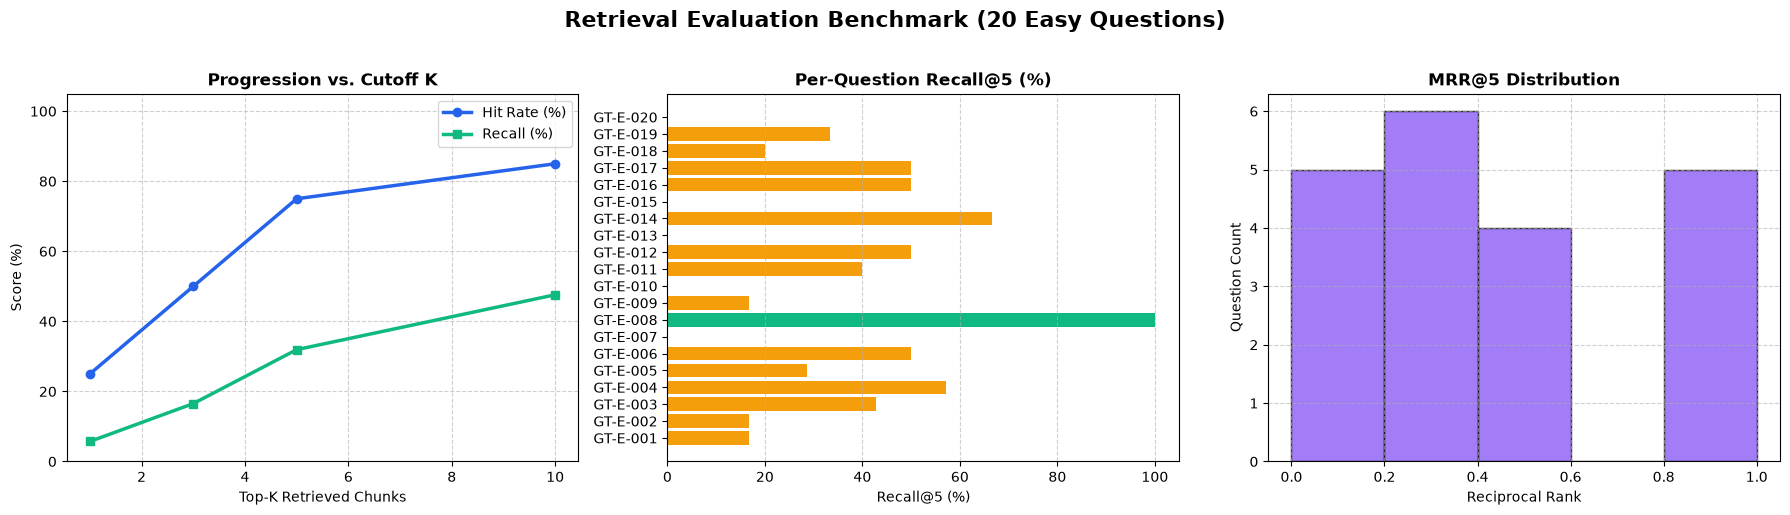

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Retrieval Evaluation Benchmark (20 Easy Questions)", fontsize=16, fontweight="bold", y=1.02)

# Chart 1: Hit Rate & Recall Progression vs K
k_vals = [1, 3, 5, 10]
hit_rates = [summary.get(f"mean_hit_rate@{k}", 0) * 100 for k in k_vals]
recalls = [summary.get(f"mean_recall@{k}", 0) * 100 for k in k_vals]

axes[0].plot(k_vals, hit_rates, marker="o", linewidth=2.5, color="#2563eb", label="Hit Rate (%)")
axes[0].plot(k_vals, recalls, marker="s", linewidth=2.5, color="#10b981", label="Recall (%)")
axes[0].set_title("Progression vs. Cutoff K", fontweight="semibold")
axes[0].set_xlabel("Top-K Retrieved Chunks")
axes[0].set_ylabel("Score (%)")
axes[0].set_ylim(0, 105)
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend()

# Chart 2: Per-Question Recall@5 Bar Chart
q_ids = results_df["id"].tolist()
rec_5 = (results_df["recall@5"] * 100).tolist()
colors = ["#10b981" if r == 100 else "#f59e0b" if r > 0 else "#ef4444" for r in rec_5]

axes[1].barh(q_ids, rec_5, color=colors)
axes[1].set_title("Per-Question Recall@5 (%)", fontweight="semibold")
axes[1].set_xlabel("Recall@5 (%)")
axes[1].set_xlim(0, 105)
axes[1].grid(axis="x", linestyle="--", alpha=0.6)

# Chart 3: MRR Distribution
mrr_vals = results_df["mrr@5"]
axes[2].hist(mrr_vals, bins=5, color="#8b5cf6", edgecolor="black", alpha=0.8)
axes[2].set_title("MRR@5 Distribution", fontweight="semibold")
axes[2].set_xlabel("Reciprocal Rank")
axes[2].set_ylabel("Question Count")
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


## 7. Retrieval Failure Analysis & Next Optimization Steps
Identify any question where `hit_rate@5 < 1.0` or `mrr@5 < 0.5` to prioritize chunking or embedding adjustments.


In [10]:
failures = results_df[results_df["hit_rate@5"] < 1.0]
if len(failures) == 0:
    print("🎉 Zero total retrieval misses at K=5! All 20 questions successfully retrieved at least one authoritative chunk.")
else:
    print(f"⚠️ Found {len(failures)} question(s) with retrieval misses at K=5:")
    for _, row in failures.iterrows():
        print(f"- [{row['id']}] {row['question']}")
        print(f"  Modality: {row['modality']}, Category: {row['category']}")

# Low ranking inspection (where hit was below rank 3)
low_ranks = results_df[(results_df["hit_rate@5"] == 1.0) & (results_df["mrr@5"] < 0.34)]
if len(low_ranks) > 0:
    print(f"\n⚠️ {len(low_ranks)} question(s) where the first relevant chunk was ranked at #4 or #5:")
    for _, row in low_ranks.iterrows():
        print(f"- [{row['id']}] {row['question']} (MRR: {row['mrr@5']})")
else:
    print("\n✅ All hits appeared in the top 3 ranks!")


⚠️ Found 5 question(s) with retrieval misses at K=5:
- [GT-E-007] What was JPMorgan Chase's total assets as of December 31, 2025?
  Modality: table, Category: Balance Sheet
- [GT-E-010] What was JPMorgan Chase's cash dividend declared per common share in 2025?
  Modality: table, Category: Per Share Data
- [GT-E-013] What was JPMorgan Chase's tangible book value per share (TBVPS) in 2025?
  Modality: table, Category: Per Share Data
- [GT-E-015] What was JPMorgan Chase's total market capitalization as of December 31, 2025?
  Modality: table, Category: Market Data
- [GT-E-020] What was JPMorgan Chase's provision for credit losses in 2025?
  Modality: table, Category: Credit Quality

⚠️ 6 question(s) where the first relevant chunk was ranked at #4 or #5:
- [GT-E-001] What was JPMorgan Chase's total net revenue for the year ended December 31, 2025? (MRR: 0.2)
- [GT-E-002] What was JPMorgan Chase's net income in 2025? (MRR: 0.2)
- [GT-E-006] How many employees did JPMorgan Chase have as of y